# Module 6 — Transformers and Attention Mechanisms

## Lesson 6.2 — Preparing Inputs for a Transformer


In Note 6.1 we watched a complete Transformer turn a line of Shakespeare into predictions. But we skipped over the very first step: how does a line of text become the tensor of numbers that the model actually receives?

That step deserves its own note, because the decisions made here shape everything downstream. How you split text into tokens decides how large the vocabulary is, how long every sequence becomes, and how much text the model can read at once. How you cut a long text into training examples decides what the model learns to predict. Get these wrong and no amount of architecture will save you; get them right and the rest of the pipeline becomes straightforward.

In this note we take Tiny Shakespeare from a raw text file to batches of training examples, ready for the model we will build in Note 6.5. Along the way, we compare three ways of tokenising text, including **byte-pair encoding**, the method used by nearly every modern language model, which we build from scratch.

**Key question:** *How does raw text become the input tensors a Transformer learns from?*

### Learning objectives
- compare character, word and subword tokenisation, with their trade-offs measured;
- explain and implement the core of byte-pair encoding (BPE);
- convert text to token IDs and embeddings;
- explain what a context window is and how tokenisation affects how much text fits in it;
- build input and target batches for next-token prediction.

### Prerequisites

 read Note 6.1. Note 5.3 covered tokenisation, vocabularies and embedding layers for words; this note builds on it.

### Setup

Run this cell first. Everything in this note runs in a few seconds, apart from training the BPE tokeniser, which takes a little longer.

**Environment and results.** The saved outputs record one CPU reference run; random seeds reduce variation but do not guarantee identical numbers across computers. Read the comparisons as evidence from that run. Training times depend on your hardware.

If packages are missing, install them into your notebook environment, then restart the kernel and run from the beginning:

```text
%pip install torch==2.14.1 numpy==2.5.4 pandas==3.0.6 matplotlib==3.11.2 scikit-learn==1.9.1 scipy==1.18.1
```

In [1]:
import os, re, collections, urllib.request
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
torch.manual_seed(0)
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cu130


## 1. The Big Picture: From Raw Text to Transformer Inputs

Here is the full journey, from a text file to what a Transformer receives in training:

1. **Split the data** into a training part and a validation part.
2. **Tokenise:** cut the text into tokens and build a vocabulary.
3. **Encode:** replace every token with its ID, giving one long sequence of integers.
4. **Cut into windows:** take chunks of fixed length, the **context window**, from that long sequence.
5. **Make targets:** for each window, the target is the same window shifted one token to the left, because the model's job is to predict the next token.
6. **Batch:** stack many windows into a tensor of shape `(batch, context)`.

The embedding layers then turn that integer tensor into vectors inside the model. Let's start with step 1. For text that tells a continuous story, like a play, we split by **position** rather than at random: the first 90% of the file for training and the last 10% for validation. A random split would scatter neighbouring lines across both sets, so the model would be validated on text it had effectively seen, just shifted by a few characters.

In [2]:
PATH = "data/shakespeare/input.txt"
os.makedirs("data/shakespeare", exist_ok=True)
if not os.path.exists(PATH):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", PATH)
text = open(PATH, encoding="utf-8").read()
n = int(0.9 * len(text))
train_text, val_text = text[:n], text[n:]          # first 90% for training, last 10% for validation
print("total characters:", len(text), "| training:", len(train_text), "| validation:", len(val_text))
print(repr(val_text[:80]))

total characters: 1115394 | training: 1003854 | validation: 111540
'?\n\nGREMIO:\nGood morrow, neighbour Baptista.\n\nBAPTISTA:\nGood morrow, neighbour Gr'


Of the 1,115,394 characters, 1,003,854 go to training and 111,540 to validation. The validation text begins in the middle of a scene from *The Taming of the Shrew*.

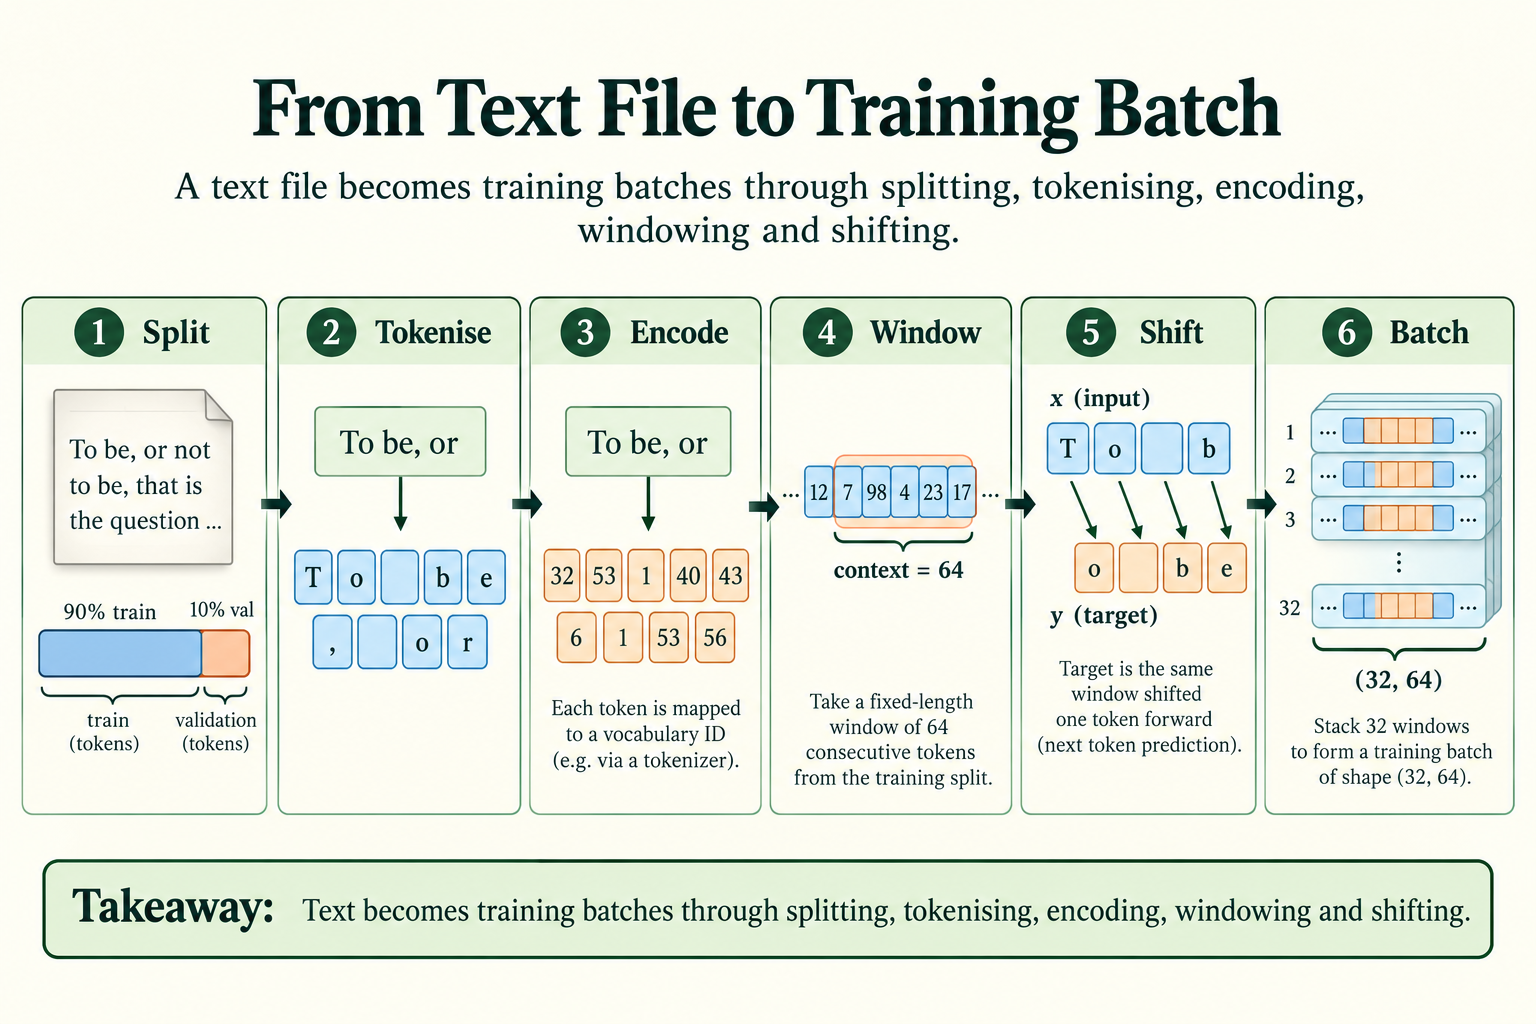

*Figure 6.2.1. Split the data without crossing the boundary, tokenise and encode, then sample windows. For next-token learning y is x shifted one position forward in the source stream. The real batch shape is (32, 64); the short example is illustrative.*

## 2. Tokenisation and Subword Tokenisation

There is no single correct way to cut text into tokens. Let's compare three, and measure what each costs.

### 2.1 Characters

The simplest choice treats every character as a token.

In [3]:
chars = sorted(set(train_text))
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
def encode_chars(s): return [stoi[c] for c in s]
def decode_chars(ids): return "".join(itos[i] for i in ids)
sample = "To be, or not to be"
print("vocabulary size:", len(chars))
print("encoded:", encode_chars(sample))
print("decoded back:", repr(decode_chars(encode_chars(sample))))
print("characters in validation text missing from the vocabulary:", len(set(val_text) - set(chars)))

vocabulary size: 65
encoded: [32, 53, 1, 40, 43, 6, 1, 53, 56, 1, 52, 53, 58, 1, 58, 53, 1, 40, 43]
decoded back: 'To be, or not to be'
characters in validation text missing from the vocabulary: 0


The training text uses 65 distinct characters, and "To be, or not to be" becomes 19 IDs, which decode back perfectly. Character tokenisation has two great strengths: the vocabulary is tiny, and **every validation character is covered in this dataset**. Every character in the validation text is already in the vocabulary (0 missing).

Its weakness is length. One token per character makes every sequence as long as possible, and the model must learn from scratch that `t`, `h`, `e` in a row form a common word.

### 2.2 Words

The opposite choice treats every word as a token. Here we split text into words, single punctuation marks and single whitespace characters, so that spaces and newlines are kept and the text could be rebuilt exactly.

In [4]:
def split_words(s):
    return re.findall(r"\w+|[^\w\s]|\s", s)       # words, single punctuation marks, single spaces/newlines
print(split_words(sample))
train_words = split_words(train_text)
word_counts = collections.Counter(train_words)
val_words = split_words(val_text)
oov = sum(w not in word_counts for w in val_words) / len(val_words)
print("distinct word-level tokens in training text:", len(word_counts))
print("tokens in training text:", len(train_words))
print(f"share of validation tokens never seen in training: {oov:.1%}")
print("examples:", [w for w in val_words if w not in word_counts][:8])

['To', ' ', 'be', ',', ' ', 'or', ' ', 'not', ' ', 'to', ' ', 'be']
distinct word-level tokens in training text: 12571
tokens in training text: 424883
share of validation tokens never seen in training: 2.6%
examples: ['affability', 'Cunning', 'sciences', 'Licio', 'Saving', 'petitioners', 'Baccare', 'Rheims']


The training text now becomes 424,883 tokens, less than half as many as with characters. But the vocabulary explodes to 12,571 distinct tokens, and 2.6% of the validation tokens never appeared in training at all: words like "affability", "petitioners" and the name "Licio". A word-level model has no way to read such words; they would all become one `<unk>` token. (The share is fairly low only because spaces and punctuation, which are never unknown, count as tokens too.)

### 2.3 Subwords: byte-pair encoding

Is there a middle path, with a modest vocabulary, shorter sequences than characters, and no unknown tokens? Yes: **subword tokenisation**, where common words become single tokens but rare words are spelled out from smaller pieces. The most widely used method is **byte-pair encoding (BPE)**. Its training algorithm is surprisingly simple:

1. Start with every word split into single characters.
2. Count every pair of **adjacent** pieces across the whole training text.
3. **Merge** the most frequent pair into a new, single piece, everywhere it occurs.
4. Repeat steps 2 and 3 for a chosen number of merges.

The list of merges, in order, *is* the tokeniser. To tokenise new text, you start from characters and apply the same merges in the same order. Let's train one with 200 merges.

In [5]:
def count_pairs(vocab):
    pairs = collections.Counter()
    for word, freq in vocab.items():
        for a, b in zip(word, word[1:]):
            pairs[(a, b)] += freq
    return pairs

def apply_merge(word, pair):
    out, i = [], 0
    while i < len(word):
        if i < len(word) - 1 and (word[i], word[i + 1]) == pair:
            out.append(word[i] + word[i + 1]); i += 2
        else:
            out.append(word[i]); i += 1
    return tuple(out)

vocab = {tuple(w): c for w, c in word_counts.items()}     # every word starts as a tuple of characters
total = lambda v: sum(len(w) * c for w, c in v.items())
merges, history = [], [(0, total(vocab))]
for step in range(200):
    best = count_pairs(vocab).most_common(1)[0][0]        # the most frequent adjacent pair
    vocab = {apply_merge(w, best): c for w, c in vocab.items()}
    merges.append(best)
    if (step + 1) % 25 == 0:
        history.append((step + 1, total(vocab)))
print("first 15 merges:", ["".join(m) for m in merges[:15]])
for k, t in history[::2]:
    print(f"after {k:>3} merges: {t:,} tokens")

first 15 merges: ['th', 'ou', 'er', 'in', 'an', 'the', 'or', 'is', 'en', 'ar', 'at', 'on', 'st', 'll', 'me']
after   0 merges: 1,003,854 tokens
after  50 merges: 778,195 tokens
after 100 merges: 715,298 tokens
after 150 merges: 678,747 tokens
after 200 merges: 654,024 tokens


The first merge joins `t` and `h` into `th`, the most common pair of characters in the text. Then come `ou`, `er`, `in` and `an`; the 6th merge combines `th` and `e` into the whole word `the`. Each merge shortens the text: the training text needs 1,003,854 tokens with no merges, 778,195 after 50 merges, 715,298 after 100 and 654,024 after 200. The first merges help the most, because they capture the most frequent pairs.

Now let's use the trained merges to tokenise some phrases.

In [6]:
def encode_bpe_word(word, cache={}):
    if word not in cache:
        pieces = tuple(word)
        for pair in merges:
            pieces = apply_merge(pieces, pair)
        cache[word] = pieces
    return cache[word]

def encode_bpe(s):
    return [p for w in split_words(s) for p in encode_bpe_word(w)]

for s in ["To be, or not to be", "the king", "Thou art a villain", "Zounds"]:
    print(f"{s!r:<24} ->", encode_bpe(s))

'To be, or not to be'    -> ['To', ' ', 'be', ',', ' ', 'or', ' ', 'not', ' ', 'to', ' ', 'be']
'the king'               -> ['the', ' ', 'king']
'Thou art a villain'     -> ['Th', 'ou', ' ', 'art', ' ', 'a', ' ', 'v', 'ill', 'ain']
'Zounds'                 -> ['Z', 'ou', 'nd', 's']


Common words such as "To", "be", "not", "the" and "king" have become single tokens. "Villain" is split into `v`, `ill`, `ain`: the tokeniser has not merged the whole word, but it reuses common pieces. And "Zounds", an old oath that the merges never formed into a word, is spelled from `Z`, `ou`, `nd`, `s`. An unseen word made from known characters can fall back to those characters. Our character-based vocabulary cannot encode a genuinely new character without an unknown-token or byte fallback.

Here are the three schemes side by side:

In [7]:
bpe_vocab = sorted(set(chars) | {"".join(m) for m in merges})
train_bpe = encode_bpe(train_text); val_bpe = encode_bpe(val_text)
print("BPE vocabulary size:", len(bpe_vocab))
print("validation pieces not in the BPE vocabulary:", sum(p not in set(bpe_vocab) for p in val_bpe))
rows = [("character", len(chars), len(train_text), len(val_text), 0.0),
        ("word", len(word_counts), len(train_words), len(val_words), oov),
        ("BPE, 200 merges", len(bpe_vocab), len(train_bpe), len(val_bpe), 0.0)]
print(f"\n{'scheme':<16} {'vocab':>7} {'train tokens':>13} {'chars/token':>12} {'unknown on val':>15}")
for name, v, tt, vt, u in rows:
    print(f"{name:<16} {v:>7,} {tt:>13,} {len(train_text) / tt:>12.2f} {u:>15.1%}")

BPE vocabulary size: 265


validation pieces not in the BPE vocabulary: 0

scheme             vocab  train tokens  chars/token  unknown on val
character             65     1,003,854         1.00            0.0%
word              12,571       424,883         2.36            2.6%
BPE, 200 merges      265       654,024         1.53            0.0%


BPE with 200 merges sits between the extremes. Its vocabulary of 265 tokens is only four times the character vocabulary, it needs 654,024 training tokens instead of 1,003,854 (each token covers 1.53 characters on average), and it has no unknown tokens. Real language models use the same algorithm with tens of thousands of merges, usually working on bytes rather than characters so that any text in any language can be encoded. The plot shows the trade-off: as the vocabulary grows, sequences get shorter.

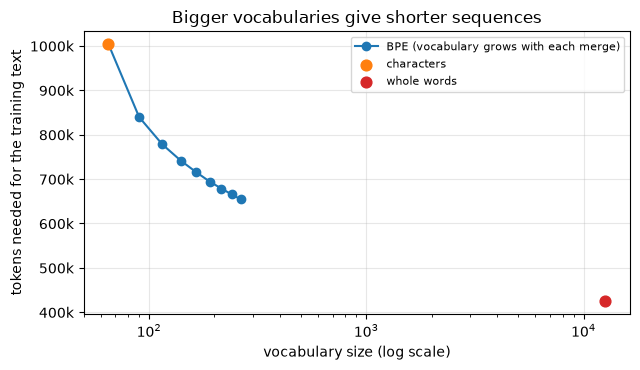

In [8]:
ks = [h[0] for h in history]; ts = [h[1] for h in history]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot([len(chars) + k for k in ks], ts, marker="o", label="BPE (vocabulary grows with each merge)")
ax.scatter([len(chars)], [len(train_text)], color="tab:orange", zorder=3, s=60, label="characters")
ax.scatter([len(word_counts)], [len(train_words)], color="tab:red", zorder=3, s=60, label="whole words")
ax.set_xscale("log"); ax.set_xlabel("vocabulary size (log scale)"); ax.set_ylabel("tokens needed for the training text")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
ax.set_title("Bigger vocabularies give shorter sequences"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

For the rest of this module we use **characters**. With 65 tokens the output head stays tiny, every pattern the model learns is visible letter by letter, and our small model can learn spelling as well as style. Keep the trade-off in mind, though: in Module 7, the pretrained models you load all come with their own subword tokenisers.

> **Common mistake:** using a model with a different tokeniser from the one it was trained with. Token ID 300 means one piece of text to one tokeniser and something completely different to another. A model and its tokeniser are a pair; always load them together.

> **Key terms**
> - **Character / word / subword tokenisation:** splitting text into single characters, whole words, or pieces in between.
> - **Byte-pair encoding (BPE):** a subword method that repeatedly merges the most frequent adjacent pair of pieces.
> - **Merge:** one BPE step, joining a pair of pieces into a new piece; the ordered list of merges defines the tokeniser.
> - **Out-of-vocabulary (OOV):** a token that never appeared in the training vocabulary.

**Check yourself.**

1. Why can a BPE tokeniser always encode a word it has never seen, while a word-level tokeniser cannot?

<details>
<summary>Worked answer</summary>

A BPE tokeniser starts every word from single characters and only then applies merges, so any word made of known characters can be encoded, at worst one character at a time. A word-level tokeniser only knows whole words it saw in training, so a new word has no entry at all.

</details>

## 3. Token IDs and Embedding Layers

With a tokeniser chosen, the whole text becomes one long sequence of integer IDs. Inside the model, an embedding layer turns each ID into a vector of `d_model` numbers, exactly as in Note 5.3.

In [9]:
train_ids = torch.tensor(encode_chars(train_text), dtype=torch.long)
val_ids = torch.tensor(encode_chars(val_text), dtype=torch.long)
print("train_ids:", tuple(train_ids.shape), train_ids.dtype, "| val_ids:", tuple(val_ids.shape))
D_MODEL = 64
tok_emb = nn.Embedding(len(chars), D_MODEL)
x = tok_emb(train_ids[:10])
print("first 10 IDs:", train_ids[:10].tolist(), "-> embeddings:", tuple(x.shape))
for name, v in [("character", len(chars)), ("BPE, 200 merges", len(bpe_vocab)), ("word", len(word_counts))]:
    print(f"embedding table for {name:<16} {v:>6,} x {D_MODEL} = {v * D_MODEL:>9,} parameters")

train_ids: (1003854,) torch.int64 | val_ids: (111540,)
first 10 IDs: [18, 47, 56, 57, 58, 1, 15, 47, 58, 47] -> embeddings: (10, 64)
embedding table for character            65 x 64 =     4,160 parameters
embedding table for BPE, 200 merges     265 x 64 =    16,960 parameters
embedding table for word             12,571 x 64 =   804,544 parameters


The training text is now one tensor of 1,003,854 integers (`int64`, which PyTorch calls `torch.long`, the type embedding layers require). The first 10 IDs become a `(10, 64)` tensor of vectors.

The choice of tokeniser also sets the size of the embedding table, and of the output head, which needs one score per vocabulary entry. With `d_model = 64`, the character vocabulary needs a table of only 4,160 parameters; BPE with 200 merges needs 16,960; the word vocabulary would need 804,544, several times more than the entire model we built in Note 6.1. For large models with vocabularies of tens of thousands, the embedding table and output head are a significant share of all parameters.

**Check yourself.**

1. If we switched our model from characters to the 12,571-word vocabulary, which two parts of the model would grow, and why?

<details>
<summary>Worked answer</summary>

The token embedding table and the output head. Both have one row (or one output) per vocabulary entry, so going from 65 to 12,571 entries would multiply their size by almost 200. With `d_model = 64`, the embedding table alone would grow from 4,160 to 804,544 parameters.

</details>

## 4. Context Windows and Sequence Length

A Transformer reads a fixed maximum number of tokens at once: its **context window** (also called context length or block size). Anything outside the window is invisible to the model when it makes a prediction. We use a context of 64 tokens.

How much *text* fits in 64 tokens depends on the tokeniser:

In [10]:
CONTEXT = 64
print(f"a context of {CONTEXT} tokens holds about:")
for name, _, tt, _, _ in rows:
    print(f"  {name:<16} {CONTEXT * len(train_text) / tt:6.0f} characters of Shakespeare")
print("\nwhat 64 characters look like:")
print(train_text[1000:1000 + CONTEXT])

a context of 64 tokens holds about:
  character            64 characters of Shakespeare
  word                151 characters of Shakespeare
  BPE, 200 merges      98 characters of Shakespeare

what 64 characters look like:
Second Citizen:
Would you proceed especially against Caius Marci


With characters, 64 tokens hold 64 characters, about one line of verse: "Second Citizen:" plus the start of the next line. With BPE (200 merges), the same 64 tokens hold about 98 characters, and with words, about 151. This is a major practical reason to use subword tokenisers: the same context window, and the same computational cost, covers more text.

Why not simply use a huge context? Because attention compares every token with every other token in the window, so its cost grows with the **square** of the context length. You will measure this in Note 6.3. Choosing a context length is a trade-off between how much the model can see and how much each training step costs.

The context window also fixes the size of the **position embedding** table: one learned vector for each position from 0 to 63. Adding it to the token embedding gives each token a different vector depending on where it sits:

In [11]:
pos_emb = nn.Embedding(CONTEXT, D_MODEL)
ids = torch.tensor(encode_chars("to be or not to be"))
h = tok_emb(ids) + pos_emb(torch.arange(len(ids)))       # (18, 64)
print("input with positions:", tuple(h.shape))
first_to, second_to = 0, 13                               # 't' of the first and second "to"
print("same token 't' -> token embeddings equal?", torch.equal(tok_emb(ids)[first_to], tok_emb(ids)[second_to]))
cos = nn.functional.cosine_similarity(h[first_to], h[second_to], dim=0).item()
print(f"after adding positions, cosine of the two 't' vectors: {cos:.3f}")
print("position-embedding parameters:", pos_emb.weight.numel())

input with positions: (18, 64)
same token 't' -> token embeddings equal? True
after adding positions, cosine of the two 't' vectors: 0.628
position-embedding parameters: 4096


In "to be or not to be", the two `t` characters (positions 0 and 13) have identical token embeddings (`True`), but after adding their position embeddings, their vectors have a cosine similarity of only 0.628. The model can now tell them apart. The position table costs 4,096 parameters (64 positions × 64 numbers). Note 6.3 explains why attention needs this information.

> **Key terms**
> - **Context window:** the maximum number of tokens the model can read at once.
> - **Position embedding:** a learned vector for each position in the context window, added to the token embedding.

**Check yourself.**

1. Our model's context is 64 characters. What happens to information that appeared 100 characters earlier when it predicts the next character?

<details>
<summary>Worked answer</summary>

It is invisible. The model only receives the 64 most recent characters, so anything earlier cannot influence the prediction at all, however important it was.

</details>

## 5. Constructing Transformer Inputs with PyTorch

Now we can build training examples. A decoder-only language model learns one task: **predict the next token**. So every training example is a pair:

- **x**, the input: a window of 64 consecutive token IDs from the text;
- **y**, the target: the same window shifted **one position to the left**, so that `y[t]` is the token that follows `x[t]`.

To make a batch, we pick random starting points in the training text and cut a window at each.

In [12]:
def get_batch(data, batch_size, context, generator):
    starts = torch.randint(0, len(data) - context - 1, (batch_size,), generator=generator)
    x = torch.stack([data[s:s + context] for s in starts])           # inputs
    y = torch.stack([data[s + 1:s + context + 1] for s in starts])   # targets: shifted one to the left
    return x, y

g = torch.Generator().manual_seed(0)
xb, yb = get_batch(train_ids, batch_size=32, context=CONTEXT, generator=g)
print("x:", tuple(xb.shape), "| y:", tuple(yb.shape))
print("x[0] as text:", repr(decode_chars(xb[0].tolist())))
print("y[0] as text:", repr(decode_chars(yb[0].tolist())))
print("possible starting points in the training text:", len(train_ids) - CONTEXT - 1)
print("next-token predictions in one batch:", xb.numel())

x: (32, 64) | y: (32, 64)
x[0] as text: 't, for his purpose in the coronation.\nI have not sounded him, no'
y[0] as text: ', for his purpose in the coronation.\nI have not sounded him, nor'
possible starting points in the training text: 1003789
next-token predictions in one batch: 2048


The batch has `x` and `y` of shape `(32, 64)`. Reading the first example as text shows the shift clearly: `x[0]` starts with `'t, for his purpose'` and ends with `'no'`, while `y[0]` starts one character later, `', for his purpose'`, and ends with `'nor'`. There are 1,003,789 possible starting points in the training text, and sampling is with replacement: repeated windows are possible and become increasingly likely over many training steps.

A single window holds 64 training examples, not one. Because of the causal mask, the prediction at position `t` can only use `x[0]` to `x[t]`, so each position is a separate next-character question with its own amount of context:

In [13]:
print(f"{'position':>8}  {'model has seen':<14}  {'must predict':<12}")
for t in range(8):
    seen = decode_chars(xb[0, :t + 1].tolist())
    print(f"{t:>8}  {seen!r:<14}  {decode_chars([yb[0, t].item()])!r:<12}")

position  model has seen  must predict
       0  't'             ','         
       1  't,'            ' '         
       2  't, '           'f'         
       3  't, f'          'o'         
       4  't, fo'         'r'         
       5  't, for'        ' '         
       6  't, for '       'h'         
       7  't, for h'      'i'         


At position 0, the model has seen only `'t'` and must predict `','`. At position 7 it has seen `'t, for h'` and must predict `'i'`. And so on, up to position 63, where it has the full window. One forward pass answers all 64 questions at once, and in a batch of 32 windows that is 2,048 predictions, each contributing to the loss. This is the parallel training that Note 6.1 promised; we use it in Note 6.6.

Finally, because the starting points are random, we draw them from a seeded `torch.Generator` so that results can be reproduced:

In [14]:
g1, g2 = torch.Generator().manual_seed(0), torch.Generator().manual_seed(0)
a, _ = get_batch(train_ids, 4, CONTEXT, g1); b, _ = get_batch(train_ids, 4, CONTEXT, g2)
print("same seed gives the same batch:", torch.equal(a, b))

same seed gives the same batch: True


The same seed gives exactly the same batch (`True`). In Note 6.6, this lets us compare different training settings on identical sequences of batches.

> **Common mistake:** shifting the targets the wrong way, or not at all. If `y` equals `x`, the model learns to copy its input, which the causal mask makes trivially easy: the loss falls to almost zero and the model learns nothing useful. If your language model's loss looks too good to be true, check the shift first.

**Check yourself.**

1. In a batch of shape `(32, 64)`, how many next-token predictions contribute to the loss?

<details>
<summary>Worked answer</summary>

32 × 64 = 2,048. Every position in every window is a separate next-token prediction.

</details>

## Putting It All Together

To turn Tiny Shakespeare into Transformer inputs, we split it by position into 1,003,854 training and 111,540 validation characters. We compared three tokenisers:

| Scheme | Vocabulary | Training tokens | Characters per token | Unknown on validation |
|---|---|---|---|---|
| Characters | 65 | 1,003,854 | 1.00 | 0.0% |
| Words | 12,571 | 424,883 | 2.36 | 2.6% |
| BPE, 200 merges | 265 | 654,024 | 1.53 | 0.0% |

BPE shortens sequences with a small vocabulary and no unknown tokens on this validation text, by repeatedly merging the most frequent adjacent pair. For our small model we chose characters.

The encoded text is one long tensor of IDs. We cut 64-token **context windows** from it at random positions, and make each target by shifting the window one token to the left. A batch of shape `(32, 64)` therefore contains 2,048 next-token predictions. Inside the model, token embeddings and position embeddings turn each ID into a 64-number vector that also knows where it sits.

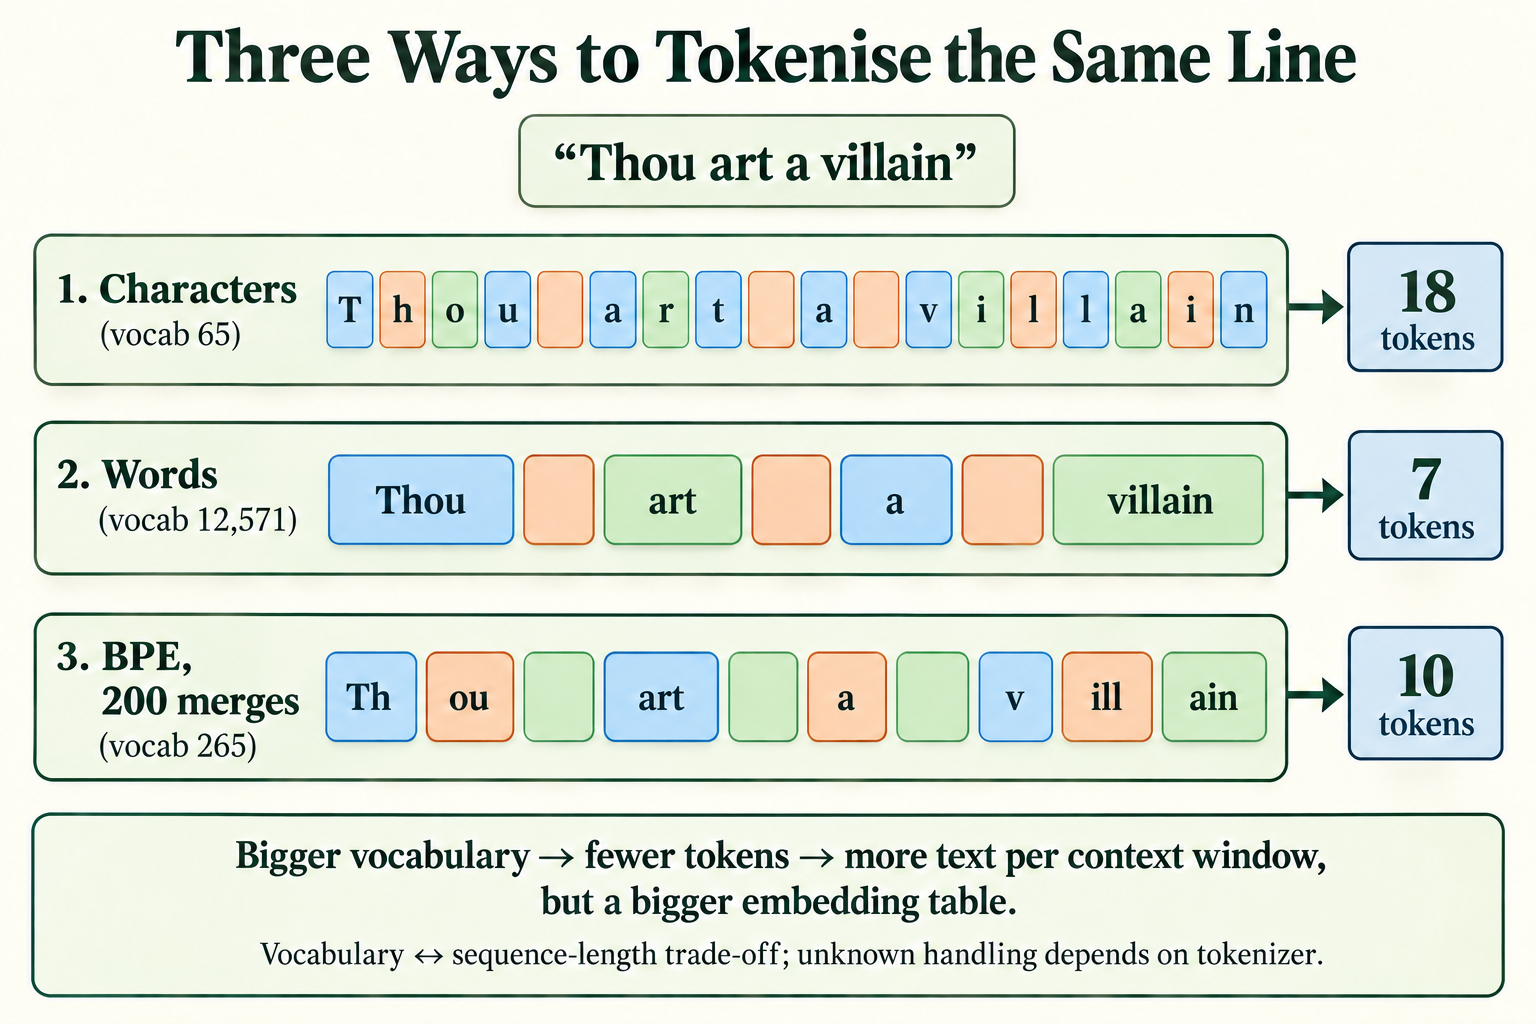

*Figure 6.2.2. This line has 18 characters including its three spaces. The lesson’s word tokenizer preserves spaces, and the illustrated BPE segmentation has 10 tokens. Vocabulary size and sequence length trade off; unknown handling depends on the tokenizer.*

## Summary

- For continuous text, split training and validation data by position, not at random.
- **Character** tokenisation has a tiny vocabulary and no unknown tokens but long sequences. **Word** tokenisation gives short sequences but a huge vocabulary and unknown words. **Subword** tokenisation (BPE) balances the two.
- **BPE** learns an ordered list of merges by repeatedly joining the most frequent adjacent pair; 200 merges cut our training text from 1,003,854 to 654,024 tokens with a 265-token vocabulary.
- A model and its tokeniser must always be used together.
- The vocabulary size sets the size of the embedding table and the output head.
- The **context window** is how many tokens the model sees at once; tokenisation decides how much text that is (64, 98 or 151 characters here).
- Training pairs are windows `x` with targets `y` shifted one token left; every position is a prediction, so a `(32, 64)` batch gives 2,048 of them.

## Glossary

| Term | Meaning |
|---|---|
| Tokenisation | Cutting text into tokens. |
| Character / word / subword tokens | Tokens that are single characters, whole words, or pieces in between. |
| Byte-pair encoding (BPE) | A subword tokeniser built by repeatedly merging the most frequent adjacent pair. |
| Merge | One BPE step joining two pieces into one. |
| Vocabulary | The set of tokens a tokeniser can produce, each with an ID. |
| Out-of-vocabulary (OOV) | A token not in the vocabulary. |
| Token ID | A token's number in the vocabulary. |
| Embedding table | The learnable lookup table from token IDs to vectors. |
| Context window | The maximum number of tokens a model reads at once. |
| Position embedding | A learned vector per position, added to token embeddings. |
| Input / target (x / y) | A window of tokens, and the same window shifted one token left. |
| Next-token prediction | The task of predicting each token from the tokens before it. |
| Batch | A stack of training examples processed together. |